In [1]:
import torch
import torch.nn as nn

In [2]:
# 固定随机种子，方便重复实验
torch.manual_seed(42)

In [3]:
# 1. 基本参数
batch_size = 2
seq_len = 4
embed_dim = 8
num_heads = 2
num_layers = 2

In [4]:
# 2. 构造输入张量
# 形状：[batch_size, seq_len, embed_dim]
x = torch.randn(batch_size, seq_len, embed_dim)

print("输入张量 x 的 shape:", x.shape)

输入张量 x 的 shape: torch.Size([2, 4, 8])


In [5]:
# 3. 创建一个 Transformer Encoder Layer
encoder_layer = nn.TransformerEncoderLayer(
    d_model=embed_dim,
    nhead=num_heads,
    dim_feedforward=32,
    batch_first=True
)

In [6]:
# 4. 使用 Transformer Encoder 堆叠多层
encoder = nn.TransformerEncoder(
    encoder_layer=encoder_layer,
    num_layers=num_layers
)

In [7]:
# 5. 前向传播
# 本实验不训练模型，只观察前向传播结果
encoder.eval()

with torch.no_grad():
    output = encoder(x)

In [8]:
# 6. 查看输入和输出的形状
print("输入 shape:", x.shape)
print("输出 shape:", output.shape)

# 7. 检查结果是否符合预期
print("输入 shape 符合预期:", x.shape == torch.Size([2, 4, 8]))
print("输入和输出 shape 相同:", x.shape == output.shape)

输入 shape: torch.Size([2, 4, 8])
输出 shape: torch.Size([2, 4, 8])
输入 shape 符合预期: True
输入和输出 shape 相同: True


In [9]:
# 任务第 6 项：修改 num_heads / num_layers，再运行一次，观察输出 shape 是否变化
# 说明：只改超参，输入张量完全不变（同一形状 [2, 4, 8]，同一份数值）。

import torch
import torch.nn as nn

# 同名同值的兜底定义，让这一节单独运行（不依赖上面的 cell）也能跑通：
batch_size, seq_len, embed_dim = 2, 4, 8
num_heads, num_layers = 2, 2

torch.manual_seed(42)
x_fixed = torch.randn(batch_size, seq_len, embed_dim)
print("固定不变的输入张量 x：shape =", tuple(x_fixed.shape))


def build_encoder(embed_dim, num_heads, num_layers, dim_feedforward=32):
    """按给定超参搭建 Transformer Encoder。"""
    layer = nn.TransformerEncoderLayer(
        d_model=embed_dim,
        nhead=num_heads,
        dim_feedforward=dim_feedforward,
        batch_first=True
    )
    return nn.TransformerEncoder(encoder_layer=layer, num_layers=num_layers)


CONFIGS = [
    (2, 2, "原始配置 (num_heads=2, num_layers=2)"),
    (4, 2, "只改 num_heads: 2 -> 4"),
    (2, 4, "只改 num_layers: 2 -> 4"),
    (4, 4, "两个都改: 4 / 4"),
    (8, 1, "num_heads=8, num_layers=1"),
]

rows = []
for nh, nl, tag in CONFIGS:
    enc = build_encoder(embed_dim, nh, nl)
    enc.eval()
    with torch.no_grad():
        out = enc(x_fixed)
    n_param = sum(p.numel() for p in enc.parameters())
    rows.append({
        "配置": tag,
        "num_heads": nh,
        "num_layers": nl,
        "参数量": n_param,
        "输出 shape": str(tuple(out.shape)),
        "输出 shape 与输入相同": tuple(out.shape) == tuple(x_fixed.shape),
    })
    print("%-38s 参数量 %6d  输出 shape %s  (与输入相同: %s)"
          % (tag, n_param, tuple(out.shape), tuple(out.shape) == tuple(x_fixed.shape)))

import pandas as pd

config_table = pd.DataFrame(rows)
print("\n================ 超参变化对输出 shape 与参数量的影响 ================")
print(config_table.to_string(index=False))
config_table.to_csv("q4_hyperparameter_experiment.csv", index=False, encoding="utf-8-sig")

# ---------- 额外验证 1：形状不变，但数值变了 ----------
enc_2_2 = build_encoder(embed_dim, 2, 2).eval()
enc_4_4 = build_encoder(embed_dim, 4, 4).eval()
with torch.no_grad():
    out_2_2 = enc_2_2(x_fixed)
    out_4_4 = enc_4_4(x_fixed)
print("\n原始配置输出（前 2 行前 4 列）：\n", out_2_2[0, :2, :4].numpy().round(3))
print("改后配置输出（前 2 行前 4 列）：\n", out_4_4[0, :2, :4].numpy().round(3))
print("两者差的范数 ||out(2,2) - out(4,4)|| = %.4f  → 形状相同但数值完全不同"
      % (out_2_2 - out_4_4).norm().item())

# ---------- 额外验证 2：nhead 必须整除 d_model ----------
print("\n【约束验证】Transformer 要求 d_model 能被 nhead 整除：")
try:
    build_encoder(embed_dim, 3, 2)          # 8 % 3 != 0
except Exception as e:
    print("  embed_dim=8, num_heads=3 → 报错：%s: %s" % (type(e).__name__, str(e).split("\n")[0][:100]))

固定不变的输入张量 x：shape = (2, 4, 8)
原始配置 (num_heads=2, num_layers=2)       参数量   1744  输出 shape (2, 4, 8)  (与输入相同: True)
只改 num_heads: 2 -> 4                   参数量   1744  输出 shape (2, 4, 8)  (与输入相同: True)
只改 num_layers: 2 -> 4                  参数量   3488  输出 shape (2, 4, 8)  (与输入相同: True)
两个都改: 4 / 4                            参数量   3488  输出 shape (2, 4, 8)  (与输入相同: True)
num_heads=8, num_layers=1              参数量    872  输出 shape (2, 4, 8)  (与输入相同: True)

================ 超参变化对输出 shape 与参数量的影响 ================
                              配置  num_heads  num_layers  参数量  输出 shape  输出 shape 与输入相同
原始配置 (num_heads=2, num_layers=2)          2           2 1744 (2, 4, 8)            True
            只改 num_heads: 2 -> 4          4           2 1744 (2, 4, 8)            True
           只改 num_layers: 2 -> 4          2           4 3488 (2, 4, 8)            True
                     两个都改: 4 / 4          4           4 3488 (2, 4, 8)            True
       num_heads=8, num_layers=1          8          

图已保存为 q4_hyperparameter_experiment.png
【结论】修改 num_heads 或 num_layers 只改变每层的头数与层数，不改变输出张量的形状；
        输入输出始终保持 [batch_size, seq_len, embed_dim]，这正是 Transformer 能逐层堆叠的原因。


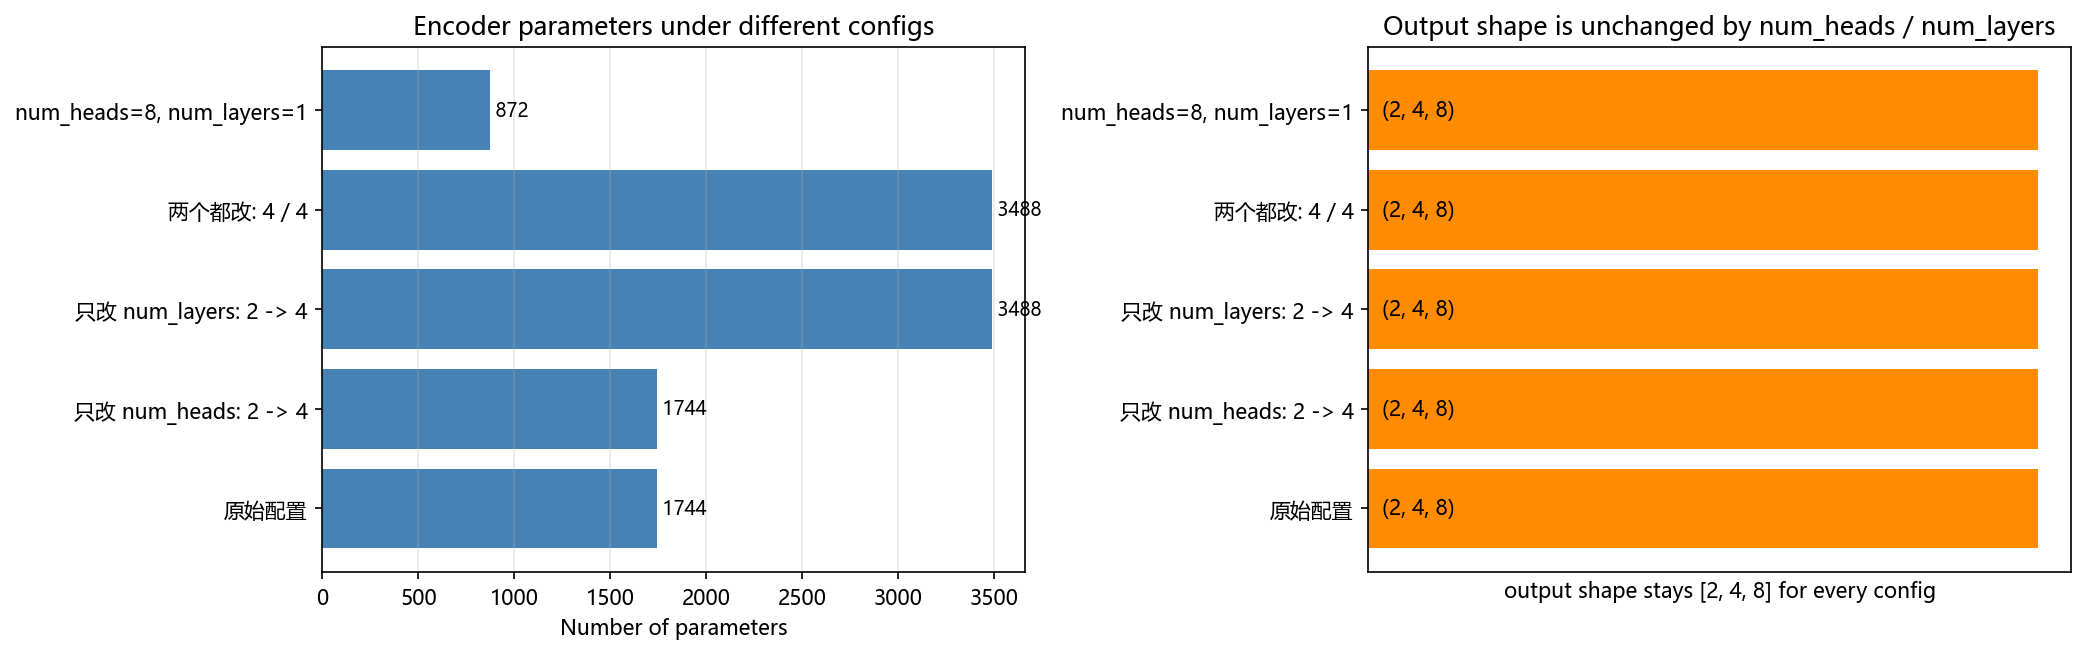

In [10]:
# 把超参与形状/参数量的关系画出来（可用于"程序运行结果截图"）

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

labels = config_table["配置"].str.replace(" (num_heads=2, num_layers=2)", "", regex=False)

axes[0].barh(labels, config_table["参数量"], color="steelblue")
axes[0].set_xlabel("Number of parameters")
axes[0].set_title("Encoder parameters under different configs")
for i, v in enumerate(config_table["参数量"]):
    axes[0].text(v, i, " %d" % v, va="center", fontsize=9)
axes[0].grid(alpha=0.3, axis="x")

axes[1].barh(labels, [1] * len(labels), color="darkorange")
axes[1].set_xlabel("output shape stays [2, 4, 8] for every config")
axes[1].set_title("Output shape is unchanged by num_heads / num_layers")
axes[1].set_xticks([])
for i, s in enumerate(config_table["输出 shape"]):
    axes[1].text(0.02, i, s, va="center", fontsize=10)
axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig("q4_hyperparameter_experiment.png", dpi=150, bbox_inches="tight")
plt.show()
print("图已保存为 q4_hyperparameter_experiment.png")
print("【结论】修改 num_heads 或 num_layers 只改变每层的头数与层数，不改变输出张量的形状；")
print("        输入输出始终保持 [batch_size, seq_len, embed_dim]，这正是 Transformer 能逐层堆叠的原因。")

## 任务第 7 项：`embed_dim` / `num_heads` / `num_layers` 分别表示什么？


### `embed_dim`（= `d_model`，本例为 8）
**每个 token 被表示成多长的向量**，也就是模型的"隐藏维度 / 特征宽度"。

- 输入张量 `[batch_size, seq_len, embed_dim] = [2, 4, 8]` 中的第三维就是它：**2 个样本、每句 4 个 token、每个 token 8 维向量**；
- 它决定了整个 Transformer 内部所有子层的数据宽度：自注意力的 Q/K/V 投影、前馈网络（FFN）的输入输出、残差连接的相加、LayerNorm 的归一化维度，全部基于 `embed_dim`；
- 它也直接决定模型的容量与计算量：自注意力权重矩阵是 $seq\_len \times seq\_len$，而 Q/K/V 与输出投影的参数都是 $\mathcal{O}(embed\_dim^2)$，FFN 通常还要放大到 $4\times embed\_dim$；
- 在真实任务里，`embed_dim` 就是"词向量维度"：字符/词先通过 Embedding 表映射成 `embed_dim` 维向量，再加上位置编码，才送进 Encoder；
- 从实验里可以看到：输入 `[2,4,8]` → 输出 `[2,4,8]`，**形状不变是设计上的必然**，因为 Encoder 每层都保持 hidden 维度不变（否则残差连接无法相加）。

### `num_heads`（= `nhead`，本例为 2，后来改成 4）
**多头注意力里"头"的个数**，即把 `embed_dim` 切成多少份、并行做多少组注意力。

- 每一头把 Q/K/V 投影到 $d_k = embed\_dim / num\_heads$ 维的子空间，各自算注意力，最后把所有头的输出**拼接起来**再过一个输出投影矩阵回到 `embed_dim`；
- 本例 `embed_dim=8, num_heads=2` → 每头 $d_k=4$；改成 `num_heads=4` → 每头 $d_k=2$；
- **作用**：不同的头可以从不同子空间关注不同的关系（语法、语义、位置、指代……），等价于"多个视角同时看序列"，增强表达能力（这也是理论问答第 4 题）；
- **硬约束**：`embed_dim` 必须能被 `num_heads` 整除（因为要均分维度）。我在实验里用 `embed_dim=8, num_heads=3` 验证过，PyTorch 会直接报错——所以能选的 num_heads 是 8 的因子：1、2、4、8；
- **注意**：单看参数量，改成 4 头后**总参数量变化很小**（Q/K/V 与输出的总维度不变），变的是"如何划分注意力子空间"；但多头会让计算/显存略增，且头数过多时每头维度太小、表达力反而下降。

### `num_layers`（本例为 2，后来改成 4）
**Encoder 里堆叠了多少个相同的 `TransformerEncoderLayer`**，也就是网络的深度。

- 每一层包含：多头自注意力 → 残差 + LayerNorm → 前馈网络（FFN）→ 残差 + LayerNorm；
- `num_layers=2` 表示这样的结构串联 2 次，**每一层都有自己独立的一套权重**（不是共享的），所以层数越多参数量线性增长（实验里 2 层 → 4 层，参数量翻倍）；
- **作用**：层数越多，越能逐层组合低级特征成高级语义，感受野/上下文交互的"深度"更大；但也会带来梯度消失风险与训练成本（这正是需要残差连接和 LayerNorm 的原因，见理论问答第 8 题）；
- **形状不变**：每层输入输出都是 `embed_dim`，所以堆多少层输出 shape 都还是 `[2, 4, 8]`——**深度只影响参数量与表达力，不影响张量形状**。

